This code is to accompany the _Are MLB Players Challenging Optimally_ Paper that I have written. This code details how I got the data from the Statcast API as well as the pybaseball Python Library and used that to determine if MLB Players are challenging optimally. 

In [1]:
import pandas as pd
import numpy as np
import pybaseball
import seaborn as sns
import matplotlib.pyplot as plt
import statsapi
from datetime import date, timedelta
from pybaseball import statcast
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score
from tqdm import tqdm
import statsmodels.formula.api as smf

In [2]:
#data_2025 = pybaseball.statcast('2021-03-01', '2025-12-01')
# This line is to save it to a parquet file for future use, so you don't have to download it again
#data_2025.to_parquet('5_year_game_data.parquet')
# Load the data from the parquet file if it was downloaded
data_2025 = pd.read_parquet('5yeardata.parquet')

This code processes baseball game data for the 2025 regular season. It filters the dataset to include only regular season games, creates new columns to represent the base state, pitch count, and unique game identifiers. The data is then sorted based on these identifiers and additional metrics are calculated, including the pitch number within the half-inning, the state of the bases and counts after each pitch, the final score at the end of each inning, and the runs scored by subtracting the initial score from the final score. From this data we also create the run expentency matrix.

In [3]:

regular_season_data_2025 = data_2025[data_2025['game_type'] == 'R']

#Creates a three character string of 1s and 0s to denote if a runner is on the current base. Ex 101 is runners on first and third
regular_season_data_2025['base'] = (
    regular_season_data_2025['on_1b'].notna().astype(int).astype(str) +
    regular_season_data_2025['on_2b'].notna().astype(int).astype(str) +
    regular_season_data_2025['on_3b'].notna().astype(int).astype(str)
)
#Concatenates balls, strikes and outs together in one string. Ex 122 is 1 ball, 2 strikes, and 2 outs.
regular_season_data_2025['count'] = (
    regular_season_data_2025['balls'].astype(str) +
    regular_season_data_2025['strikes'].astype(str) +
    regular_season_data_2025['outs_when_up'].astype(str)
)
# Creates a index of the game string, the inning and the half-inning so it identifies each unique half inning
regular_season_data_2025['index'] = (
    regular_season_data_2025['game_pk'].astype(str) +
    regular_season_data_2025['inning'].astype(str) +
    regular_season_data_2025['inning_topbot'].astype(str)
)
data_2025_sorted = regular_season_data_2025.sort_values(by=['index', 'at_bat_number', 'pitch_number'])
data_2025_sorted['pitch_in_half_inning'] = (
    data_2025_sorted.groupby('index')
    .cumcount() + 1
)
# The base state after the pitch
data_2025_sorted['post_base'] = (
    data_2025_sorted.groupby('index')['base'].shift(-1)
)
#The count state after the pitch
data_2025_sorted['post_count'] = (
    data_2025_sorted.groupby('index')['count'].shift(-1)
)
data_2025_sorted['inning_end_score'] = data_2025_sorted.groupby('index')['post_bat_score'].transform('last')
#Calculates the number of runs scored that inning from that point.
data_2025_sorted['runs_scored'] =  data_2025_sorted['inning_end_score'] - data_2025_sorted['bat_score'] 

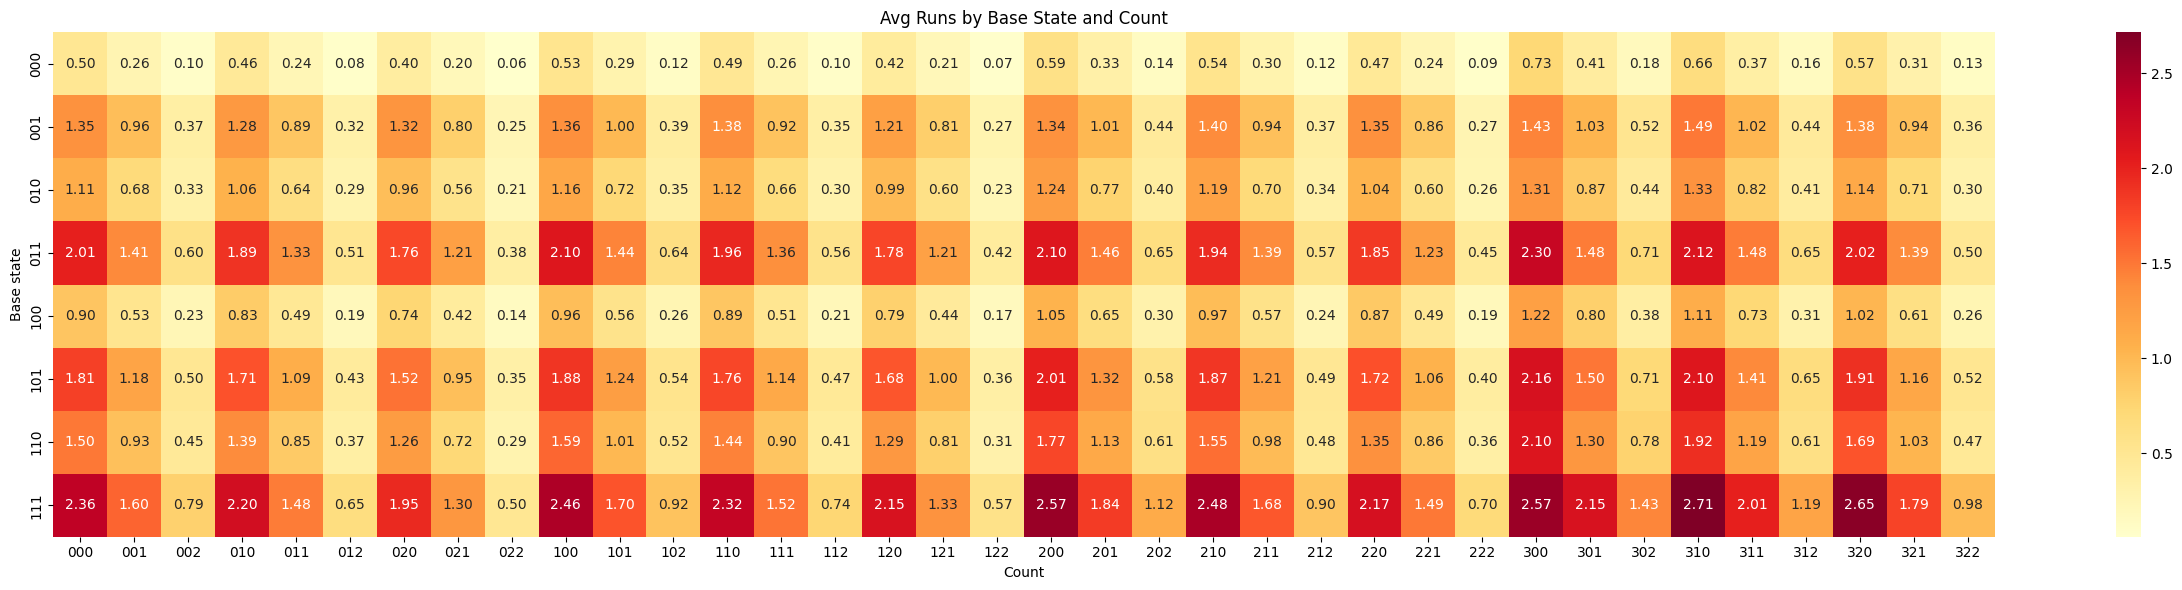

In [4]:
# Average runs scored from this pitch to the end of the half-inning, grouped by base state (runners on 1B/2B/3B) and ball-strike-out-count

avg_runs_matrix = (
    data_2025_sorted.groupby(['base', 'count'])['runs_scored']
    .mean()
    .unstack()
)
fig, ax = plt.subplots(figsize=(25, 6))
sns.heatmap(avg_runs_matrix.astype(float), annot=True, fmt='.2f', cmap='YlOrRd', ax=ax)
ax.set_title('Avg Runs by Base State and Count')
ax.set_xlabel('Count')
ax.set_ylabel('Base state')
plt.tight_layout()
plt.show()

These next few cells is the code that have have written to scrape play-by-play data from the API. The first cell has two helper functions in it. The first is a function that I used to calculate the location of runners on the base paths before the pitch, including any pre-pitch movement. The second function is one that counts the number of automatic ball and strikes since called due to pitch clock violations before the current pitch since this is not in the data. Below these two functions is the code to scrape from the API, which scrapes data that is available and calculates new fields.

In [7]:
# Calculate the location of runners prior to the pitch, returns the ocupants as a dictionary, the base state as a string, and if any runners moved before the challenge event.
def get_runners(play, prev_play, event_index):
    """
    Returns the base occupancy, base state, and whether any runners moved before the challenge event.
    
    Starts from the previous play's base occupancy and updates it based on the runners' movements in the current play. If any runner moved before the challenge event, pre_movement is set to 1.
    
    Args:
        play (dict): The current play data.
        prev_play (dict): The previous play data.
        event_index (int): The index of the challenge event in the current play's events.
        
    Returns:
        - bases (dict): A dictionary representing the occupancy of each base.
        - base_state (str): A string representing the base state as a three-character string of 1s (occupied) and 0s (unoccupied).
        - pre_movement (int): 1 if any runner moved before the challenge event, otherwise 0. 
    """
    pre_movement = 0
    bases = {"1B": None, "2B": None, "3B": None}
    B_1 = 0
    B_2 = 0
    B_3 = 0
    # The starting values for bases come from the previous pitch
    if prev_play is not None:
        if prev_play.get("matchup", {}).get("postOnFirst"):
            bases["1B"] = prev_play.get("matchup", {}).get("postOnFirst").get("id")
            B_1 = 1
        if prev_play.get("matchup", {}).get("postOnSecond"):
            bases["2B"] = prev_play.get("matchup", {}).get("postOnSecond").get("id")
            B_2 = 1
        if prev_play.get("matchup", {}).get("postOnThird"):
            bases["3B"] = prev_play.get("matchup", {}).get("postOnThird").get("id")
            B_3 = 1
    # Sort the runners by their playIndex to ensure we process them in the order they moved.
    runners_sorted = sorted(
        play.get("runners", []),
        key=lambda r: r.get("details", {}).get("playIndex", -1)
    )
    for runner in runners_sorted:
        play_index = runner.get("details", {}).get("playIndex")
        # Check if the runner's playIndex is less than the event_index, indicating that the runner moved before the challenge event.
        if play_index is not None and play_index < event_index:
            # If any runner moved before the challenge event, set pre_movement to 1
            pre_movement = 1
            current_movement = runner.get("movement", {})
            start = current_movement.get("start")
            end = current_movement.get("end")
            name = runner.get("details", {}).get("runner", {}).get("id", {})

            # A runner leaving a base always vacates it, even if the recorded occupant ID doesn't match (e.g., pinch runners)
            if start in ("1B", "2B", "3B"):
                bases[start] = None
                if start == "1B":
                    B_1 = 0
                elif start == "2B":
                    B_2 = 0
                elif start == "3B":
                    B_3 = 0
            # Mark the ending base as occupied by this runner
            if end in ("1B", "2B", "3B"):
                bases[end] = name
                if end == "1B":
                    B_1 = 1 
                elif end == "2B":
                    B_2 = 1
                elif end == "3B":
                    B_3 = 1 
    return bases, f"{B_1}{B_2}{B_3}", pre_movement

def automatic_calls_before(play, event_index):
    """
    Counts the number of automatic calls that occurred before the challenge event in the play due to pitch clock violations.
    
    Args:
        play (dict): The current play data.
        event_index (int): The index of the current play.
    
    Returns:
        int: The count of automatic calls before the challenge event.
    """
    count = 0
    for e in play["playEvents"][:event_index]:
        desc = (e.get("details", {}).get("description") or "").lower()
        if "automatic" in desc:
            count += 1
    return count

def side_of(player_id):
    """
    Determines whether a player is on the home or away team based on their player ID.
    
    Args:
        player_id (int): The ID of the player.
        
    Returns:
        str: 'home' if the player is on the home team, 'away' if on the away team, or 'unknown' if not found.
    """
    if player_id in home_ids:
        return 'home'
    if player_id in away_ids:
        return 'away'
    return 'unknown'

In [8]:
yesterday = (date.today() - timedelta(days=1)).strftime("%m/%d/%Y")
# Uses the statsapi to get the schedule of all games in the 2026 season up to yesterday's date. Filters for regular season games and initializes an empty DataFrame to store challenged plays
all_games = pd.DataFrame(statsapi.schedule(start_date="03/01/2026", end_date=yesterday))
regular_games = all_games[all_games['game_type'] == 'R']
columns = ['game_date', 'game_id', 'start_time', 'inning', 'inning_top_bottom', 'at_bat_index', 'pitch_number', 'challenger_name', 'team', 'id', 'position', 'challenger_side', 'original_call', 'overturned', 'final_call', 'prev_balls', 'prev_strikes',
           'prev_outs', 'prev_bases', 'prev_bases_state', 'pre_movement', 'challenges_available', 'challenges_remaining']
challenged_data_frame = pd.DataFrame(columns = columns)
pulled_ids = []
print("Beginning to pull data for all games in the 2026 season...")
for index, cur_game in tqdm(regular_games.iterrows(), total=len(regular_games), desc="Pulling games"):
    # Only process games that are not postponed and have not already been pulled
    if cur_game["status"] != 'Postponed':
        if cur_game["game_id"] not in pulled_ids:
            home_team_challenges = 2
            away_team_challenges = 2
            game_date = cur_game["game_date"]
            pulled_ids.append(cur_game["game_id"])
            # Use the statsapi to get detailed information about the current game, including plays and player data
            game = statsapi.get("game", {"gamePk": cur_game["game_id"]})

            # Map each player ID in this game to the side they played for
            home_ids = {p["person"]["id"] for p in game["liveData"]["boxscore"]["teams"]["home"]["players"].values()}
            away_ids = {p["person"]["id"] for p in game["liveData"]["boxscore"]["teams"]["away"]["players"].values()}

            prev_play = None
            prev_inning = 1
            prev_top_bottom = "top"
            away_team = game.get("gameData", {}).get("teams", {}).get("away", {}).get("name", {})
            home_team = game.get("gameData", {}).get("teams", {}).get("home", {}).get("name", {})
            # Iterate through all plays in the game to identify and record challenged plays, including details about the challenge, the players involved, and the game state at the time of the challenge
            for play in game["liveData"]["plays"]["allPlays"]:
                at_bat = play.get("about", {}).get("atBatIndex") + 1
                already_handled_event = ""
                batter_id = play["matchup"]["batter"]["id"]
                pitcher_id = play["matchup"]["pitcher"]["id"]
                # Loop through each event in the play to find challenges and record their details, including the original call, final call, and whether the challenge was overturned
                for event in play["playEvents"]:
                    if event == already_handled_event:
                        continue
                    cur_play_details = event["details"]
                    cur_play_count = event["count"]
                    if cur_play_details.get('call'):
                        final_call = cur_play_details['call']['code']
                        if final_call == 'C':
                            final_call = 'Strike'
                        elif final_call == 'B':
                            final_call = 'Ball'
                        # Check if the event is a challenged pitch result and if it meets the criteria for recording (i.e., it has a review, the final call is a strike or ball, and the review type is 'MJ')
                        if event["details"]["hasReview"] == True and (final_call == 'Strike' or final_call == 'Ball') and event["reviewDetails"]["reviewType"] == 'MJ':
                            raw_pitch_number = event.get("pitchNumber")
                            # Calculate the pitch number in the current at bat, accounting for any automatic calls that occurred before the challenge
                            automatic_before = automatic_calls_before(play, event["index"])
                            pitch_number = raw_pitch_number + automatic_before if raw_pitch_number is not None else None
                            challenger_id = event["reviewDetails"].get("player", {}).get("id")
                            # Determine what the original pitch call was if the pitch was challenged and overturned
                            if event["reviewDetails"]["isOverturned"] == True:
                                if final_call == 'Strike':
                                    original_call = 'Ball'
                                else:
                                    original_call = 'Strike'
                            else:
                                if final_call == 'Strike':
                                    original_call = 'Strike'
                                else:
                                    original_call = 'Ball'
                            # Determine the  count prior to the challenge
                            if cur_play_details["isStrike"] == True:
                                prev_strikes = cur_play_count["strikes"] - 1
                            else:
                                prev_strikes = cur_play_count["strikes"]
                            if cur_play_details["isBall"] == True:
                                prev_balls = cur_play_count["balls"] - 1
                            else:
                                prev_balls = cur_play_count["balls"]
                            # Determine if the challenger was the batter, pitcher or catcher and assign the appropriate team name based on the half-inning
                            if challenger_id == batter_id:
                                challenged_position = 'Batter'
                                team_name = away_team if play.get('about', {}).get("halfInning") == 'top' else home_team
                            elif challenger_id == pitcher_id:
                                challenged_position = 'Pitcher'
                                team_name = home_team if play.get('about', {}).get("halfInning") == 'top' else away_team
                            else:
                                challenged_position = 'Catcher'
                                team_name = home_team if play.get('about', {}).get("halfInning") == 'top' else away_team
                            # Determine the number of challenges available before the challenge, as well as the number of challenges remaining after the challenge. Add a additional challenge if it is extra innings and the team that challenges had no challenges left at the end of the 9th inning.
                            challenges_available = home_team_challenges if team_name == home_team else away_team_challenges
                            if (challenges_available == 0) and (play.get('about', {}).get("inning") > 9):
                                challenges_available = 1
                            if team_name == home_team:
                                if not event["reviewDetails"].get("isOverturned"):
                                    home_team_challenges -= 1
                                challenges_remaining = home_team_challenges
                            if team_name == away_team:
                                if not event["reviewDetails"].get("isOverturned"):
                                    away_team_challenges -= 1
                                challenges_remaining = away_team_challenges
                            if prev_inning != play.get('about', {}).get("inning") or prev_top_bottom != play.get('about', {}).get("halfInning"):
                                prev_play = None
                            # Get the base occupancy and state prior to the challenge event, as well as whether any runners moved before the challenge event
                            updated_base_runners, updated_base_state, pre_movement = get_runners(play, prev_play, event["index"])
                            new_challenge = pd.DataFrame([{'game_date': game_date, 'game_id': cur_game["game_id"], 'start_time': play["about"]["startTime"], 'inning': play.get('about', {}).get("inning"),
                                                           'inning_top_bottom': play.get('about', {}).get("halfInning"), 'at_bat_index': at_bat, 'pitch_number': pitch_number, 'challenger_name': event["reviewDetails"].get("player", {}).get("fullName"), 'team': team_name,
                                                           'id': challenger_id, 'position': challenged_position, 'challenger_side': side_of(challenger_id), 'original_call': original_call, 'overturned': event["reviewDetails"].get("isOverturned"),
                                                           'final_call': final_call, 'prev_balls': prev_balls, 'prev_strikes': prev_strikes, 'prev_outs': cur_play_count['outs'], 'prev_bases': updated_base_runners, 'prev_bases_state': updated_base_state,
                                                           'pre_movement': pre_movement, 'challenges_available': challenges_available, 'challenges_remaining': challenges_remaining}])
                            challenged_data_frame = pd.concat([challenged_data_frame, new_challenge], ignore_index=True)
                # Special handling for challenges that happen on the last pitch of the at bat, since these are recorded differently in the data. This checks if the play result indicates a challenged pitch and if the review type is 'MJ', then it processes the last play event to extract the necessary details for recording the challenge
                if ("challenged (pitch result)" in (play.get("result", {}).get("description") or "")) and play["reviewDetails"].get("reviewType") == "MJ":
                    # In these cases, the last play event is the play that contains the pitch information that correlates with the challenge
                    last_play = play["playEvents"][-1]
                    last_play_details = play["playEvents"][-1]["details"]
                    already_handled_event = play["playEvents"][-1]
                    # If the last play is unique play that does not have the pitch information or if it has a pickoff, then we need to go to the second to the last pitch for the information
                    if last_play_details.get("isStrike") is None or "pickoff" in (last_play_details.get("description") or "").lower():
                        last_play_details = play["playEvents"][-2]["details"]
                        last_play = play["playEvents"][-2]
                        already_handled_event = play["playEvents"][-2]
                    raw_pitch_number = last_play.get("pitchNumber")
                    # Calculate the pitch number in the current at bat, accounting for any automatic calls that occurred before the challenge
                    automatic_before = automatic_calls_before(play, last_play["index"])
                    pitch_number = raw_pitch_number + automatic_before if raw_pitch_number is not None else None
                    challenger_id = play["reviewDetails"].get("player", {}).get("id")
                    last_play_count = last_play["count"]
                    final_call = last_play_details['call']['code']
                    if final_call == 'C':
                        final_call = 'Strike'
                    elif final_call == 'B':
                        final_call = 'Ball'
                    if (final_call == 'Strike' or final_call == 'Ball'):
                        # Determine what the original pitch call was if the pitch was challenged and overturned
                        if play["reviewDetails"]["isOverturned"] == True:
                            if final_call == 'Strike':
                                original_call = 'Ball'
                            else:
                                original_call = 'Strike'
                        else:
                            if final_call == 'Strike':
                                original_call = 'Strike'
                            else:
                                original_call = 'Ball'
                        # Determine the count prior to the challenge
                        if last_play_details["isStrike"] == True:
                            prev_strikes = (last_play_count["strikes"]) - 1
                        else:
                            prev_strikes = last_play_count["strikes"]
                        if last_play_details["isBall"] == True:
                            prev_balls = (last_play_count["balls"]) - 1
                        else:
                            prev_balls = last_play_count["balls"]
                        prev_outs = last_play_count["outs"]
                        # Determine if the challenger was the batter, pitcher or catcher and assign the appropriate team name based on the half-inning
                        if challenger_id == batter_id:
                            challenged_position = 'Batter'
                            team_name = away_team if play.get('about', {}).get("halfInning") == 'top' else home_team
                        elif challenger_id == pitcher_id:
                            challenged_position = 'Pitcher'
                            team_name = home_team if play.get('about', {}).get("halfInning") == 'top' else away_team
                        else:
                            challenged_position = 'Catcher'
                            team_name = home_team if play.get('about', {}).get("halfInning") == 'top' else away_team
                        if prev_inning != play.get('about', {}).get("inning") or prev_top_bottom != play.get('about', {}).get("halfInning"):
                            prev_play = None
                        # Determine the number of challenges available before the challenge, as well as the number of challenges remaining after the challenge. Add a additional challenge if it is extra innings and the team that challenges had no challenges left at the end of the 9th inning
                        challenges_available = home_team_challenges if team_name == home_team else away_team_challenges
                        if (challenges_available == 0) and (play.get('about', {}).get("inning") > 9):
                            challenges_available = 1
                        if team_name == home_team:
                            if not play["reviewDetails"].get("isOverturned"):
                                home_team_challenges -= 1
                            challenges_remaining = home_team_challenges
                        if team_name == away_team:
                            if not play["reviewDetails"].get("isOverturned"):
                                away_team_challenges -= 1
                            challenges_remaining = away_team_challenges
                        # Get the base occupancy and state prior to the challenge event, as well as whether any runners moved before the challenge event
                        updated_base_runners, updated_base_state, pre_movement = get_runners(play, prev_play, last_play["index"])
                        new_challenge = pd.DataFrame([{'game_date': game_date, 'game_id': cur_game["game_id"], 'start_time': play["about"]["startTime"], 'inning': play.get('about', {}).get("inning"),
                                                       'inning_top_bottom': play.get('about', {}).get("halfInning"), 'at_bat_index': at_bat, 'pitch_number': pitch_number, 'challenger_name': play["reviewDetails"].get("player", {}).get("fullName"), 'team': team_name,
                                                       'id': challenger_id, 'position': challenged_position, 'challenger_side': side_of(challenger_id), 'original_call': original_call, 'overturned': play["reviewDetails"].get("isOverturned"),
                                                       'final_call': final_call, 'prev_balls': prev_balls, 'prev_strikes': prev_strikes, 'prev_outs': prev_outs, 'prev_bases': updated_base_runners,
                                                       'prev_bases_state': updated_base_state, 'pre_movement': pre_movement, 'challenges_available': challenges_available, 'challenges_remaining': challenges_remaining}])
                        challenged_data_frame = pd.concat([challenged_data_frame, new_challenge], ignore_index=True)
                prev_inning = play.get('about', {}).get("inning")
                prev_top_bottom = play.get('about', {}).get("halfInning")
                prev_play = play

print(f"Number of Challenges: {len(challenged_data_frame)}")
print(f"Number of Offensive Challenges : {len(challenged_data_frame[challenged_data_frame['position'] == 'Batter'])}")
print(f"Number of Defensive Challenges: {len(challenged_data_frame[challenged_data_frame['position'].isin(['Pitcher', 'Catcher'])])}")
challenged_data_frame.to_csv('challenged_data_frame.csv', index=False)
#Uncomment if reading the csv in from a file
#challenged_data_frame = pd.read_csv('challenged_data_frame.csv')

Beginning to pull data for all games in the 2026 season...


Pulling games: 100%|██████████| 2459/2459 [18:05<00:00,  2.26it/s]

Number of Challenges: 10557
Number of Offensive Challenges : 4766
Number of Defensive Challenges: 5791


The next few cells focus on the second part of getting the data, which was the PyBaseball library. The first cell are helper functions the second cell is code that gets the apporiate data using the PyBaseball library and merges it with the challenged data frame.

In [9]:
def should_batter_challenge(row):
    """
    Determines if the batter should challenge a pitch based on its location and the original call. 
    
    The horizontal zone edge is half the plate width, 17/24 ft (8.5 in). This ignores the ball's radius, so the zone is narrower than the rule, which counts a pitch as a strike if any part of the ball touches the plate.
    
    Args:
        row (pd.Series): A row from the DataFrame containing pitch data.
        
    Returns:
        bool: True if the batter should challenge the pitch, False otherwise.
    """
    in_zone = (
        np.abs(row['plate_x']) <= (17/24) and
        row['sz_bot'] <= row['plate_z'] <= row['sz_top']
    )
    return row['description'] == 'called_strike' and not in_zone

def should_defense_challenge(row):
    """
    Determines if the defense should challenge a pitch based on its location and the original call.
    
    The horizontal zone edge is half the plate width, 17/24 ft (8.5 in). This ignores the ball's radius, so the zone is narrower than the rule, which counts a pitch as a strike if any part of the ball touches the plate.
    
    Args:
        row (pd.Series): A row from the DataFrame containing pitch data.
        
    Returns:
        bool: True if the defense should challenge the pitch, False otherwise.
    """
    in_zone = (
        np.abs(row['plate_x']) <= (17/24) and
        row['sz_bot'] <= row['plate_z'] <= row['sz_top']
    )
    return row['description'] == 'ball' and in_zone

def dist_from_zone(row):
    """
    Calculates the distance in feet of a pitch from the strike zone.
    
    The horizontal zone edge is half the plate width, 17/24 ft (8.5 in). This ignores the ball's radius, so the zone is narrower than the rule, which counts a pitch as a strike if any part of the ball touches the plate.
    
    Args:
        row (pd.Series): A row from the DataFrame containing pitch data.
    
    Returns:
        float: The Euclidean distance in feet of the pitch from the strike zone.
    
    """
    x_miss = max(np.abs(row['plate_x']) - (17/24), 0)
    z_miss = max(row['sz_bot'] - row['plate_z'], 0, row['plate_z'] - row['sz_top'])
    
    return np.sqrt(x_miss**2 + z_miss**2)

def base_runner_info(base_state):
    """
    Summarizes the base runner information based on the base state string.
    
    Args:
        base_state (str): A three-character string representing the base state (e.g., '101' for runners on first and third).
    
    Returns:
        str: A summary of the base runner situation ('RISP', 'Bases Empty', or 'Runner on First').
    """
    first = base_state[0] == '1'
    second = base_state[1] == '1'
    third = base_state[2] == '1'
    if second or third:
        return 'RISP'
    elif not first and not second and not third:
        return 'Bases Empty'
    else:
        return 'Runner on First'
    
def run_model(data, X_cols, label):
    """
    Trains a Gradient Boosting Classifier on the provided data and evaluates its performance. Trains and prints the evaliuation metrics for the model, including the best hyperparameters found during grid search and the AUC score on the test set. 
    Also prints the feature importances of the trained model. Uses stratified train-test split to ensure that the class distribution is preserved in both the training and test sets.
    
    Args:
        data (pd.DataFrame): The input DataFrame containing features and target variable.
        X_cols (list): List of column names to be used as features for the model.
        label (str): A label for the model being trained, used for printing results.
    
    Returns:
        GradientBoostingClassifier: The best model found during grid search.
    """
    dummy_cols = [c for c in ['bucketed_base_state'] if c in X_cols]
    X = pd.get_dummies(data[X_cols], columns=dummy_cols)
    y = data['overturned_int']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    parameters = {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.001, 0.01, 0.05, 0.1],
        'max_depth': [2, 3, 4],
        'subsample': [0.8, 1.0],
    }
    model = GradientBoostingClassifier(random_state=42)
    grid = GridSearchCV(model, parameters, cv=5, scoring='roc_auc', n_jobs=-1)
    
    grid.fit(X_train, y_train)
    
    print(f"Best parameters for {label}: {grid.best_params_}")
    print(f"Best cross-validated AUC for {label}: {grid.best_score_:.3f}")
    
    best_model = grid.best_estimator_
    
    preds = best_model.predict(X_test)
    probs = best_model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probs)
    
    print(f"\n--- {label} ---")
    print(f"n={len(data)}, AUC={auc:.3f}")
    print(classification_report(y_test, preds))

    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    print("Feature importances:")
    print(importances)
    return best_model

def walk_updated_state(base_state):
    """
    Updates the base state after a walk and calculates the number of runs scored.
    
    Args:
        base_state (str): A three-character string representing the base state before the walk (e.g., '101' for runners on first and third).
    
    Returns:
        Str: A three-character string representing the new base state after the walk.
        int: The number of runs scored as a result of the walk.
    """
    first = base_state[0] == '1'
    second = base_state[1] == '1'
    third = base_state[2] == '1'
    
    run_scores = int(first and second and third)
    
    new_first = True
    new_second = first or second
    new_third = (first and second) or third

    return f"{int(new_first)}{int(new_second)}{int(new_third)}", run_scores

def updated_state(row):
    """
    If the current pitch is a ball and it results in a walk (4 balls), updates the base state and calculates the number of runs scored. Otherwise, returns the current base state and 0 runs scored.
    
    Args:
        row (pd.Series): A row from the DataFrame containing pitch data, including 'balls' and 'base'.
    
    Returns:
        pd.Series: A Series containing the updated base state and the number of runs scored.
    """
    if row['balls'] +  1 == 4:
        updated_base_info, runs_scored = walk_updated_state(row['base'])
        return pd.Series([updated_base_info, runs_scored])
    else: return pd.Series([row['base'], 0])  
    
def get_or_re(cur_row):
    """
    Calculates the expected runs based on the original call of the pitch and the previous state of the game. 
    
    Args:
        cur_row (pd.Series): A row from the DataFrame containing pitch data, including 'original_call', 'prev_balls', 'prev_strikes', 'prev_outs', and 'prev_bases_state'.
    
    Returns:
        float: The expected runs based on the original call and previous state.
    """
    if cur_row['original_call'] == 'Strike':
        org_balls = cur_row['prev_balls'] 
        org_strikes = cur_row['prev_strikes'] + 1
        if org_strikes == 3:
            count = "00" + str(cur_row['prev_outs'] + 1)
            return avg_runs_matrix.get(count, {}).get(cur_row['prev_bases_state'], 0)
    if cur_row['original_call'] == 'Ball':
        org_balls = cur_row['prev_balls'] + 1
        org_strikes = cur_row['prev_strikes']
        if org_balls == 4:
            org_outs = cur_row['prev_outs']
            new_base_state, new_runs = walk_updated_state(cur_row['prev_bases_state'])
            count = "00" + str(org_outs)
            return avg_runs_matrix.get(count, {}).get(new_base_state, 0) + new_runs
    count = str(org_balls) + str(org_strikes) + str(cur_row['prev_outs'])
    return avg_runs_matrix.get(count, {}).get(cur_row['prev_bases_state'], 0)

def get_abs_re(cur_row):
    """
    Calculates the expected runs if the original call is overturned, based on the previous state of the game.
    
    Args:
        cur_row (pd.Series): A row from the DataFrame containing pitch data, including 'original_call', 'prev_balls', 'prev_strikes', 'prev_outs', and 'prev_bases_state'.
    
    Returns:
        float: The expected runs if the original call is overturned, based on the previous state.
    """
    if cur_row['original_call'] == 'Strike':
        abs_balls = cur_row['prev_balls'] + 1
        if abs_balls == 4:
            new_base_state, new_runs = walk_updated_state(cur_row['prev_bases_state'])
            count = "00" + str(cur_row['prev_outs'])
            return avg_runs_matrix.get(count, {}).get(new_base_state, 0) + new_runs
        else:
            count = str(abs_balls) + str(cur_row['prev_strikes']) + str(cur_row['prev_outs'])
            return avg_runs_matrix.get(count, {}).get(cur_row['prev_bases_state'], 0)
    else:
        abs_strikes = cur_row['prev_strikes'] + 1
        if abs_strikes == 3:
            count = "00" + str(cur_row['prev_outs'] + 1)
            return avg_runs_matrix.get(count, {}).get(cur_row['prev_bases_state'], 0)
        else:
            count = str(cur_row['prev_balls']) + str(abs_strikes) + str(cur_row['prev_outs'])
            return avg_runs_matrix.get(count, {}).get(cur_row['prev_bases_state'], 0)


In [31]:
# Use the statcast function to pull pitch data from the 2026 season
#yesterday = (date.today() - timedelta(days=1)).strftime('%Y-%m-%d')
pitches = statcast(start_dt='2026-03-25', end_dt=yesterday)
pitches = pitches[pitches['game_type'] == 'R']
called_pitches = pitches[pitches['description'].isin(['called_strike', 'ball'])].copy()

#Drop rows missing zone coordinates (small number, safe to drop)
called_pitches = called_pitches.dropna(subset=['plate_x', 'plate_z', 'sz_top', 'sz_bot'])
# Calcualte the base state for each pitch based on the occupancy of first, second, and third base. The base state is represented as a three-character string where each character is '1' if the corresponding base is occupied and '0' if it is empty. For example, '101' indicates runners on first and third base, while '000' indicates bases are empty.
called_pitches['base_state'] = (
    called_pitches['on_1b'].notna().astype(int).astype(str) +
    called_pitches['on_2b'].notna().astype(int).astype(str) +
    called_pitches['on_3b'].notna().astype(int).astype(str)
)
# Calculate the distance each pitch is from the strike zone and use the distance to determine if the pitch was in the strike zone or not (within 1e-9 feet)
called_pitches['miss_distance'] = called_pitches.apply(dist_from_zone, axis=1)
called_pitches['in_zone'] = called_pitches['miss_distance'] < 1e-9
called_pitches['was_call_wrong'] = (
    (called_pitches['description'] == 'called_strike') & ~called_pitches['in_zone'] |
    (called_pitches['description'] == 'ball') & called_pitches['in_zone']
)
# Merge the api dataframe of the challenges with the statcast dataframe of all the pitches
challenged_data_frame = pd.read_csv('challenged_data_frame.csv', dtype={'prev_bases_state': str})
challenged_merged = challenged_data_frame.merge(
    called_pitches[['game_pk', 'at_bat_number', 'pitch_number',
                     'plate_x', 'plate_z', 'sz_top', 'sz_bot',
                     'balls', 'strikes', 'miss_distance']],
    left_on=['game_id', 'at_bat_index', 'pitch_number'],
    right_on=['game_pk', 'at_bat_number', 'pitch_number']
)
# Calculate other necessary variables for the model, including whether the challenge was overturned, the base runner situation, the expected runs for the original call and if it was overturned as well as the difference in expected runs and the 
# actual change in expected runs based on the challenge outcome. The 're_value' is calculated based on whether the challenger was the batter or defense, with positive values for batter challenges and negative values for defense challenges.
challenged_merged['overturned_int'] = challenged_merged['overturned'].astype(int)
challenged_merged['bucketed_base_state'] = challenged_merged['prev_bases_state'].apply(base_runner_info)
challenged_merged['actual_post_re'] = challenged_merged.apply(get_or_re, axis=1)
challenged_merged['abs_post_re'] = challenged_merged.apply(get_abs_re, axis=1)
challenged_merged['re_diff'] = challenged_merged['abs_post_re'] - challenged_merged['actual_post_re']
challenged_merged['actual_re_change'] = np.where(challenged_merged['overturned'], challenged_merged['re_diff'], 0)           
challenged_merged['re_value'] = np.where(challenged_merged['position'] == 'Batter', challenged_merged['actual_re_change'], -challenged_merged['actual_re_change'])


api_features = ['prev_balls', 'prev_strikes', 'prev_outs', 'bucketed_base_state', 'challenges_available']
batter_challenges = challenged_merged[challenged_merged['original_call'] == 'Strike'].dropna(subset = api_features).copy()
defense_challenges = challenged_merged[challenged_merged['original_call'] == 'Ball'].dropna(subset = api_features).copy()

# Code to run the model to determine the most important variables for a batter challenge to be overturned
print("=" * 60)
print("BATTER MODELS")
batter_api_model = run_model(batter_challenges, api_features, "Batter - API only")

batter_challenges = batter_challenges.reset_index(drop=True)
batter_challenges['miss_distance_in'] = batter_challenges['miss_distance'] * 12
# Run a logistic regression model to determine the most important variables for a batter challenge to be overturned, using the previous balls, strikes, outs, challenges available, and the bucketed base state as predictors. The model is fitted using the statsmodels library and the summary of the model is printed.
batter_logit_model = smf.logit(
    "overturned_int ~ prev_balls + prev_strikes + prev_outs + challenges_available + C(bucketed_base_state)",
    data=batter_challenges
).fit()
print(batter_logit_model.summary())

results_df = pd.DataFrame({
    'Coefficient': batter_logit_model.params,
    'Std Error': batter_logit_model.bse,
    'z': batter_logit_model.tvalues,
    'P>|z|': batter_logit_model.pvalues,
    'Odds Ratio': np.exp(batter_logit_model.params)
}).round(4)

results_df = results_df.reset_index().rename(columns={'index': 'Variable'})
print(results_df.to_csv(sep='\t', index=False))

# Code to run the model to determine the most important variables for a defense challenge to be overturned
print("=" * 60)
print("DEFENSE MODELS")
print("=" * 60)
defense_api_model = run_model(defense_challenges, api_features, "Batter - API only")

defense_challenges = defense_challenges.reset_index(drop=True)
defense_challenges['miss_distance_in'] = defense_challenges['miss_distance'] * 12
# Run a logistic regression model to determine the most important variables for a defensivechallenge to be overturned, using the previous balls, strikes, outs, challenges available, and the bucketed base state as predictors. The model is fitted using the statsmodels library and the summary of the model is printed.
defense_logit_model = smf.logit(
    "overturned_int ~ prev_balls + prev_strikes + prev_outs + challenges_available + C(bucketed_base_state)",
    data=defense_challenges
).fit()
print(defense_logit_model.summary())

results_df = pd.DataFrame({
    'Coefficient': defense_logit_model.params,
    'Std Error': defense_logit_model.bse,
    'z': defense_logit_model.tvalues,
    'P>|z|': defense_logit_model.pvalues,
    'Odds Ratio': np.exp(defense_logit_model.params)
}).round(4)

results_df = results_df.reset_index().rename(columns={'index': 'Variable'})
print(results_df.to_csv(sep='\t', index=False))

This is a large query, it may take a moment to complete


100%|██████████| 227/227 [03:58<00:00,  1.05s/it]


BATTER MODELS
Best parameters for Batter - API only: {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
Best cross-validated AUC for Batter - API only: 0.597

--- Batter - API only ---
n=4766, AUC=0.582
              precision    recall  f1-score   support

           0       0.56      0.71      0.62       488
           1       0.57      0.41      0.48       466

    accuracy                           0.56       954
   macro avg       0.56      0.56      0.55       954
weighted avg       0.56      0.56      0.55       954

Feature importances:
prev_strikes                           0.803502
bucketed_base_state_Bases Empty        0.094244
prev_balls                             0.067093
bucketed_base_state_Runner on First    0.016336
challenges_available                   0.016281
prev_outs                              0.001301
bucketed_base_state_RISP               0.001243
dtype: float64
Optimization terminated successfully.
         Current function value:

These next few cells focus on the variables with the highest importance to the rate of a pitch being overturned, which is the number of strikes in a count for batters, and the number of balls for the defense.

In [36]:
batter_challenges_summary = batter_challenges.groupby('prev_strikes').agg(
    challenge_count=('overturned', 'size'),
    overturn_count=('overturned', 'sum'),
    overturn_rate=('overturned', 'mean'),
    miss_by_strikes = ('miss_distance_in', 'mean')
).round(2)
batter_challenges_summary['overturn_rate'] = batter_challenges_summary['overturn_rate'].round(2)
print(batter_challenges_summary)

defensive_challenges_summary = defense_challenges.groupby('prev_balls').agg(
    challenge_count=('overturned', 'size'),
    overturn_count=('overturned', 'sum'),
    overturn_rate=('overturned', 'mean'),
    miss_by_balls = ('miss_distance_in', 'mean')
).round(2)
defensive_challenges_summary['overturn_rate'] = defensive_challenges_summary['overturn_rate'].round(2)
print(defensive_challenges_summary)

              challenge_count  overturn_count  overturn_rate  miss_by_strikes
prev_strikes                                                                 
0                        1617             949           0.59             1.91
1                        1530             733           0.48             1.56
2                        1619             646           0.40             1.28
            challenge_count  overturn_count  overturn_rate  miss_by_balls
prev_balls                                                               
0                      2424            1549           0.64           1.18
1                      1514             877           0.58           1.33
2                      1056             568           0.54           1.49
3                       797             363           0.46           1.72


In [37]:

def bounds(group):
    """
    Calculate the worst-case bounds for the overturn rate in a group of challenges.
    
    Args:
        group (pd.DataFrame): A DataFrame containing a group of challenges.
    
    Returns:
        n (int): The number of challenges in the group.
        k / n (float): The observed overturn rate in the group.
        low (float): The lower bound of the overturn rate, assuming the ambiguous challenge is counted as a non-overturn.
        high (float): The upper bound of the overturn rate, assuming the ambiguous challenge is counted as an overturn.
    """
    n = len(group)
    k = group['overturned'].sum()
    # Worst case in each direction: the challenge is in this group
    # as a confirmed challenge (removing it) or as an overturn (adding it)
    low = k / (n + 1 - 1)  # rate with the ambiguous challenge counted as an extra non-overturn
    high = (k + 1) / n     # rate with it counted as an overturn
    return n, k / n, low, high

for name, g in [
    ('batters, 2 strikes', batter_challenges[batter_challenges['prev_strikes'] == 2]),
    ('batters, 0 strikes', batter_challenges[batter_challenges['prev_strikes'] == 0]),
    ('defense, 3 balls', defense_challenges[defense_challenges['prev_balls'] == 3]),
    ('defense, 0 balls', defense_challenges[defense_challenges['prev_balls'] == 0]),
]:
    n, rate, low, high = bounds(g)
    print(f"{name}: n={n}, rate={rate:.1%}, range {low:.1%} to {high:.1%}")

# Calculating the percentage difference in overturn rate between 2 strikes and 0 strikes for batter challenges
b2 = batter_challenges[batter_challenges['prev_strikes'] == 2]['overturned'].mean()
b0 = batter_challenges[batter_challenges['prev_strikes'] == 0]['overturned'].mean()
print(f"batters: relative {(b0 - b2) / b0:.1%}, points {(b0 - b2) * 100:.1f}")

# Calculating the percentage difference in overturn rate between 3 balls and 0 balls for defensive challenges
f3 = defense_challenges[defense_challenges['prev_balls'] == 3]['overturned'].mean()
f0 = defense_challenges[defense_challenges['prev_balls'] == 0]['overturned'].mean()
print(f"defense: relative {(f0 - f3) / f0:.1%}, points {(f0 - f3) * 100:.1f}")

batters, 2 strikes: n=1619, rate=39.9%, range 39.9% to 40.0%
batters, 0 strikes: n=1617, rate=58.7%, range 58.7% to 58.8%
defense, 3 balls: n=797, rate=45.5%, range 45.5% to 45.7%
defense, 0 balls: n=2424, rate=63.9%, range 63.9% to 63.9%
batters: relative 32.0%, points 18.8
defense: relative 28.7%, points 18.4


The next cell is delving further into the importance of the number of strikes for batter challenges. It shows how many overturns I would estimate there to to be if the batters had challenged with zero strikes and not two, and what that value would have been in terms of the number of runs scored.

In [38]:
zero_strike_batter = batter_challenges[batter_challenges['prev_strikes'] == 0]
two_strike_batter = batter_challenges[batter_challenges['prev_strikes'] == 2]

zero_strike_rate = zero_strike_batter['overturned'].mean()
two_strike_rate = two_strike_batter['overturned'].mean()
n_two_strike = len(two_strike_batter)

# Calculate the difference in overturn rates between 0-strike and 2-strike situations
rate_gap = zero_strike_rate - two_strike_rate
# Estimate the number of hypothetical extra overturns that could have occurred if the 2-strike overturn rate matched the 0-strike overturn rate
hypothetical_extra_successes = rate_gap * n_two_strike

# Calculate the average value per successful overturn in 2-strike situations and estimate the total missed value based on the hypothetical extra successes
avg_value_per_success = two_strike_batter[two_strike_batter['overturned']]['re_value'].mean()
estimated_missed_value = hypothetical_extra_successes * avg_value_per_success

print(f"""
0-strike overturn rate: {zero_strike_rate:.3f}
2-strike overturn rate: {two_strike_rate:.3f}
2-strike challenge volume: {n_two_strike}
Rate gap: {rate_gap:.3f}   
Estimated missed overturns: {hypothetical_extra_successes:.2f}
Average value per overturn: {avg_value_per_success:.3f}
Estimated missed value: {estimated_missed_value:.3f} runs
Estimated missed value per team: {estimated_missed_value / 30:.3f} runs
""")


0-strike overturn rate: 0.587
2-strike overturn rate: 0.399
2-strike challenge volume: 1619
Rate gap: 0.188   
Estimated missed overturns: 304.17
Average value per overturn: 0.350
Estimated missed value: 106.464 runs
Estimated missed value per team: 3.549 runs



The next cell is delving further into the importance of the number of balls for defensive challenges. It shows how many overturns I would estimate there to to be if the defenses had challenged with zero balls and not three, and what that value would have been in terms of the number of runs scored.

In [39]:
zero_balls_defense = defense_challenges[defense_challenges['prev_balls'] == 0]
three_balls_defense = defense_challenges[defense_challenges['prev_balls'] == 3]

zero_balls_rate = zero_balls_defense['overturned'].mean()
three_balls_rate = three_balls_defense['overturned'].mean()
n_three_balls = len(three_balls_defense)

# Calculate the difference in overturn rates between 0-ball and 3-ball situations
rate_gap = zero_balls_rate - three_balls_rate
# Estimate the number of hypothetical extra overturns that could have occurred if the 3-ball overturn rate matched the 0-ball overturn rate
hypothetical_extra_successes = rate_gap * n_three_balls

# Calculate the average value per successful overturn in 3-ball situations and estimate the total missed value based on the hypothetical extra successes
avg_value_per_success = three_balls_defense[three_balls_defense['overturned']]['re_value'].mean()
estimated_missed_value = hypothetical_extra_successes * avg_value_per_success

print(f"""
0-ball overturn rate: {zero_balls_rate:.3f}
3-ball overturn rate: {three_balls_rate:.3f}
3-ball challenge volume: {n_three_balls}
Rate gap: {rate_gap:.3f}   
Estimated missed overturns: {hypothetical_extra_successes:.2f}
Average value per overturn: {avg_value_per_success:.3f}
Estimated missed value: {estimated_missed_value:.3f} runs
Estimated missed value per team: {estimated_missed_value / 30:.3f} runs
""")


0-ball overturn rate: 0.639
3-ball overturn rate: 0.455
3-ball challenge volume: 797
Rate gap: 0.184   
Estimated missed overturns: 146.30
Average value per overturn: 0.474
Estimated missed value: 69.367 runs
Estimated missed value per team: 2.312 runs



These next three cells are the code that I used to determine the batter and the catcher examples. The first one are the helper functions, the second two are the code. The second cell is the batter examples, the third cell is the catcher examples.

In [40]:
def is_monotonic_decreasing(row, metric, levels):
    """
    Checks if the values of a specified metric in a row are monotonically decreasing across three base states (0, 1, 2).
    
    Args:
        row (pd.Series): A row from the DataFrame containing the metric values.
        metric (str): The name of the metric to check for monotonicity.
        levels (list): A list of levels (e.g., [0, 1, 2]) to check for monotonicity.
        
    Returns:
        bool: True if the values are monotonically decreasing, False otherwise.
    """
    values = [row[(metric, b)] for b in levels]
    return all(values[i] >= values[i+1] for i in range(len(values)-1))

def is_monotonic_increasing(row, metric, levels):
    """
    Checks if the values of a specified metric in a row are monotonically increasing across three base states (0, 1, 2).
    
    Args:
        row (pd.Series): A row from the DataFrame containing the metric values.
        metric (str): The name of the metric to check for monotonicity.
        levels (list): A list of levels (e.g., [0, 1, 2]) to check for monotonicity.
    
    Returns:
        bool: True if the values are monotonically decreasing, False otherwise.
    """
    values = [row[(metric, b)] for b in levels]
    return all(values[i] <= values[i+1] for i in range(len(values)-1))

In [41]:
levels = [0,1,2]
# Set a minimum number of challenges required for each strike count to be included in the analysis
min_per_group = 3

batter_challenges_empty = batter_challenges[batter_challenges['bucketed_base_state'] == 'Bases Empty']
counts_def = batter_challenges_empty.groupby(['challenger_name', 'prev_strikes']).size().unstack(fill_value=0)

# Require at least some minimum at all three strike counts
qualified_def = counts_def[(counts_def.get(0, 0) >= min_per_group) &
                             (counts_def.get(1, 0) >= min_per_group) &
                             (counts_def.get(2, 0) >= min_per_group)]

print(f"Players with {min_per_group}+ challenges at all 3 strike counts: {len(qualified_def)}")

# Get list of qualified players and filter the batter challenges to only include those players
qualified_names_def = qualified_def.index
candidate_def = batter_challenges_empty[batter_challenges_empty['challenger_name'].isin(qualified_names_def)]

# Summarize overturn rate and average miss distance by player and strike count, then unstack to have strike counts as columns
summary_def = candidate_def.groupby(['challenger_name', 'prev_strikes']).agg(
    overturn_rate=('overturned', 'mean'),
    avg_miss_distance=('miss_distance_in', 'mean')
).unstack()
print(summary_def)

# Calculate if
flags = pd.DataFrame(index = summary_def.index)
flags['overturn_monotonic'] = summary_def.apply(lambda r: is_monotonic_decreasing(r, 'overturn_rate', levels), axis=1)
flags['miss_dist_monotonic'] = summary_def.apply(lambda r: is_monotonic_increasing(r, 'avg_miss_distance', levels), axis=1)

# Players matching the trend on BOTH metrics, perfectly
perfect_matches_index = flags[flags['overturn_monotonic'] & flags['miss_dist_monotonic']]
print(f"Players with a perfectly monotonic match on both metrics: {len(perfect_matches_index)}")    

perfect_matches = summary_def.loc[perfect_matches_index.index]
print(perfect_matches[['overturn_rate', 'avg_miss_distance']])
gaps = pd.DataFrame(index = perfect_matches.index)
gaps['overturn_gap'] = perfect_matches[('overturn_rate', 0)] - perfect_matches[('overturn_rate', 2)]
gaps['miss_dist_gap'] = perfect_matches[('avg_miss_distance', 2)] - perfect_matches[('avg_miss_distance', 0)]
print(gaps.sort_values(('miss_dist_gap'), ascending=False))

#Calculates the number of times the overturn rate increases as the number of strikes increases (which is a violation of the expected trend) and the number of times the average miss distance decreases as the number of strikes increases (also a violation of the expected trend)
flags['overturn_violations'] = summary_def.apply(lambda r: sum(
    r[('overturn_rate', b)] < r[('overturn_rate', b+1)] for b in [0, 1]
), axis=1)
# Calculates the number of times the average miss distance decreases as the number of strikes increases (which is a violation of the expected trend)
flags['miss_dist_violations'] = summary_def.apply(lambda r: sum(
    r[('avg_miss_distance', b)] > r[('avg_miss_distance', b+1)] for b in [0, 1]
), axis=1)
# Calculates the total number of violations by summing the overturn violations and miss distance violations for each player
flags['total_violations'] = flags['overturn_violations'] + flags['miss_dist_violations']

# Total sample size per player (across all 3 strike counts, bases empty)
flags['total_n'] = counts_def.loc[summary_def.index].sum(axis=1)

# Sort: fewest violations first, then largest sample size as tiebreaker
order = (
    flags[['total_violations', 'total_n']]
    .sort_values(['total_violations', 'total_n'], ascending=[True, False])
    .index
)
ranked = summary_def.loc[order]
print(ranked)
print(flags.loc[order, ['total_violations', 'total_n']])

# Zach Neto is the batter that the largest sample size with the fewest violations
neto_empty = batter_challenges_empty[
    (batter_challenges_empty['challenger_name'] == 'Zach Neto')
].copy().groupby('prev_strikes').agg(
    challenge_count = ('overturned', 'size'),
    overturn_rate = ('overturned', 'mean'),
    avg_miss_distance = ('miss_distance_in', lambda x: x.mean().round(2))
).round(2)
print(neto_empty)

Players with 3+ challenges at all 3 strike counts: 44
                      overturn_rate                     avg_miss_distance  \
prev_strikes                      0         1         2                 0   
challenger_name                                                             
Alex Bregman               0.600000  0.333333  0.500000          2.068621   
Ben Rice                   0.750000  0.400000  0.666667          2.161495   
Bryan Reynolds             0.500000  0.500000  0.833333          2.003698   
Bryce Harper               0.333333  0.285714  0.500000          1.535969   
Ceddanne Rafaela           0.200000  0.000000  0.166667          0.957354   
Coby Mayo                  0.400000  0.750000  1.000000          1.336917   
Cole Carrigg               0.500000  0.200000  0.000000          1.284651   
Colt Keith                 0.750000  0.250000  0.333333          1.564361   
Edouard Julien             0.250000  0.800000  0.250000          1.324397   
Esteury Ruiz          

In [43]:
levels = [0, 1, 2, 3]
# Set a minimum number of challenges required for each ball count to be included in the analysis
min_per_group = 3

defensive_challenges_empty = defense_challenges[defense_challenges['bucketed_base_state'] == 'Bases Empty']
counts_def = defense_challenges_empty.groupby(['challenger_name', 'prev_balls']).size().unstack(fill_value=0)

# Require at least some minimum at all four ball counts
qualified_def = counts_def[(counts_def.get(0, 0) >= min_per_group) &
                             (counts_def.get(1, 0) >= min_per_group) &
                             (counts_def.get(2, 0) >= min_per_group) &
                             (counts_def.get(3, 0) >= min_per_group)]

print(f"Players with {min_per_group}+ challenges at all 4 ball counts: {len(qualified_def)}")
qualified_names_def = qualified_def.index
candidate_def = defense_challenges_empty[defense_challenges_empty['challenger_name'].isin(qualified_names_def)]

summary_def = candidate_def.groupby(['challenger_name', 'prev_balls']).agg(
    overturn_rate=('overturned', 'mean'),
    avg_miss_distance=('miss_distance', 'mean')
).unstack()

print(summary_def)

flags = pd.DataFrame(index=summary_def.index)
flags['overturn_monotonic'] = summary_def.apply(lambda r: is_monotonic_decreasing(r, 'overturn_rate', levels), axis=1)
flags['miss_dist_monotonic'] = summary_def.apply(lambda r: is_monotonic_increasing(r, 'avg_miss_distance', levels), axis=1)

# Players matching the trend on BOTH metrics, perfectly
perfect_matches_index = flags[flags['overturn_monotonic'] & flags['miss_dist_monotonic']].index
print(f"Players with a perfectly monotonic match on both metrics: {len(perfect_matches)}")
perfect_matches = summary_def.loc[perfect_matches_index]
print(perfect_matches[['overturn_rate', 'avg_miss_distance']])

# Calculate the gaps in overturn rate and average miss distance between 0 balls and 3 balls for players with perfect monotonic matches
gaps = pd.DataFrame(index=perfect_matches.index)
gaps['overturn_gap'] = perfect_matches[('overturn_rate', 0)] - perfect_matches[('overturn_rate', 3)]
gaps['miss_dist_gap'] = perfect_matches[('avg_miss_distance', 3)] - perfect_matches[('avg_miss_distance', 0)]
print(gaps.sort_values(by=['miss_dist_gap', 'overturn_gap'], ascending=False))

# Austin Wells is a catcher with a large sample size and a perfect monotonic match on both metrics, so we can analyze his performance in detail
wells_empty = challenged_merged[
    (challenged_merged['challenger_name'] == 'Austin Wells') &
    (challenged_merged['bucketed_base_state'] == 'Bases Empty')
].copy().groupby('prev_balls').agg(
    challenge_count = ('overturned', 'size'),
    overturn_rate = ('overturned', 'mean'),
    overturned = ('overturned', 'sum'),
    avg_miss_distance = ('miss_distance', lambda x: (x.mean() * 12).round(2))
).round(2)
print(wells_empty)

Players with 3+ challenges at all 4 ball counts: 53
                   overturn_rate                                \
prev_balls                     0         1         2         3   
challenger_name                                                  
Adley Rutschman         0.714286  0.600000  0.833333  0.800000   
Alejandro Kirk          0.869565  0.600000  0.454545  0.500000   
Andrew Knizner          0.750000  0.400000  0.833333  0.666667   
Austin Hedges           0.692308  0.714286  0.272727  0.375000   
Austin Wells            0.805556  0.727273  0.615385  0.363636   
Brandon Valenzuela      0.400000  0.375000  0.200000  0.800000   
Brett Sullivan          0.666667  0.800000  0.100000  1.000000   
Cal Raleigh             0.666667  0.833333  0.500000  0.375000   
Carlos Narváez          0.600000  0.428571  0.600000  0.750000   
Carson Kelly            0.863636  0.578947  0.833333  0.777778   
Carter Jensen           0.666667  0.571429  0.400000  0.615385   
Christian Vázquez       

These final two cells are the code for the additional visualizations I created. First for batters and second for defenses.

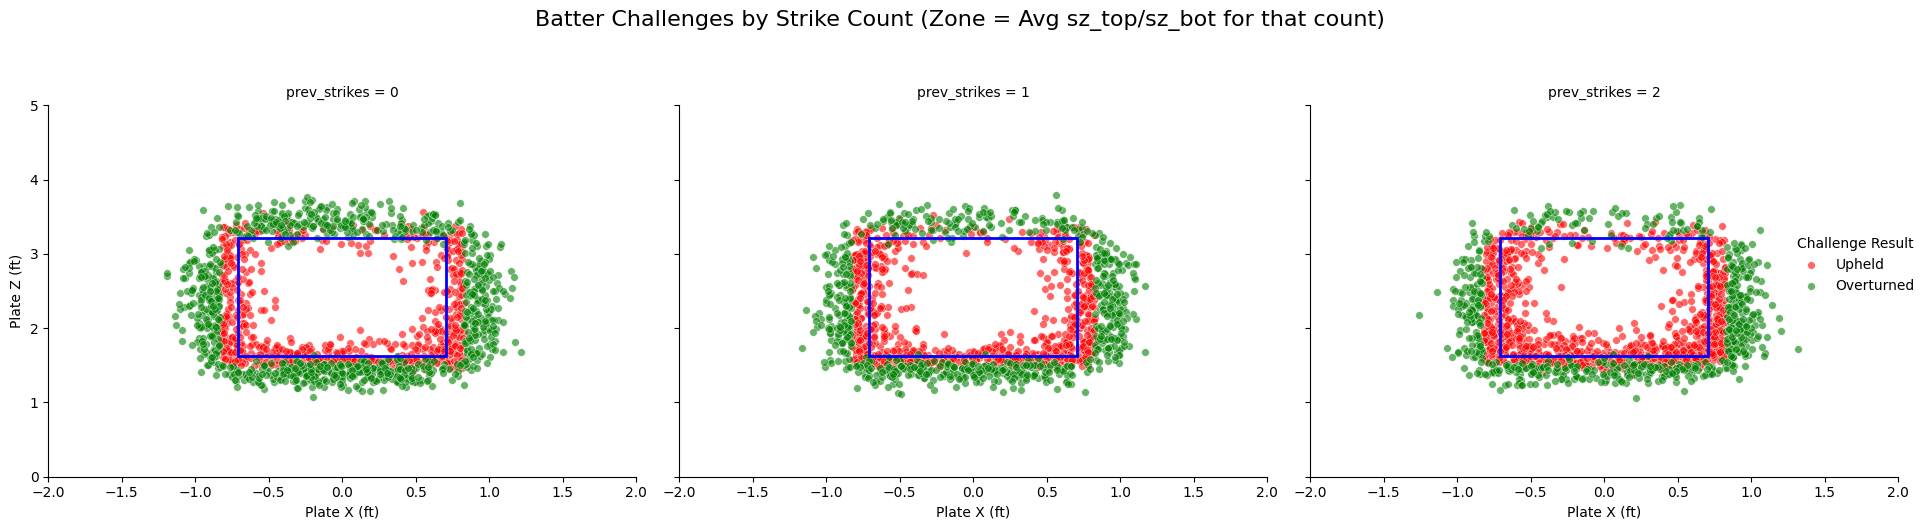

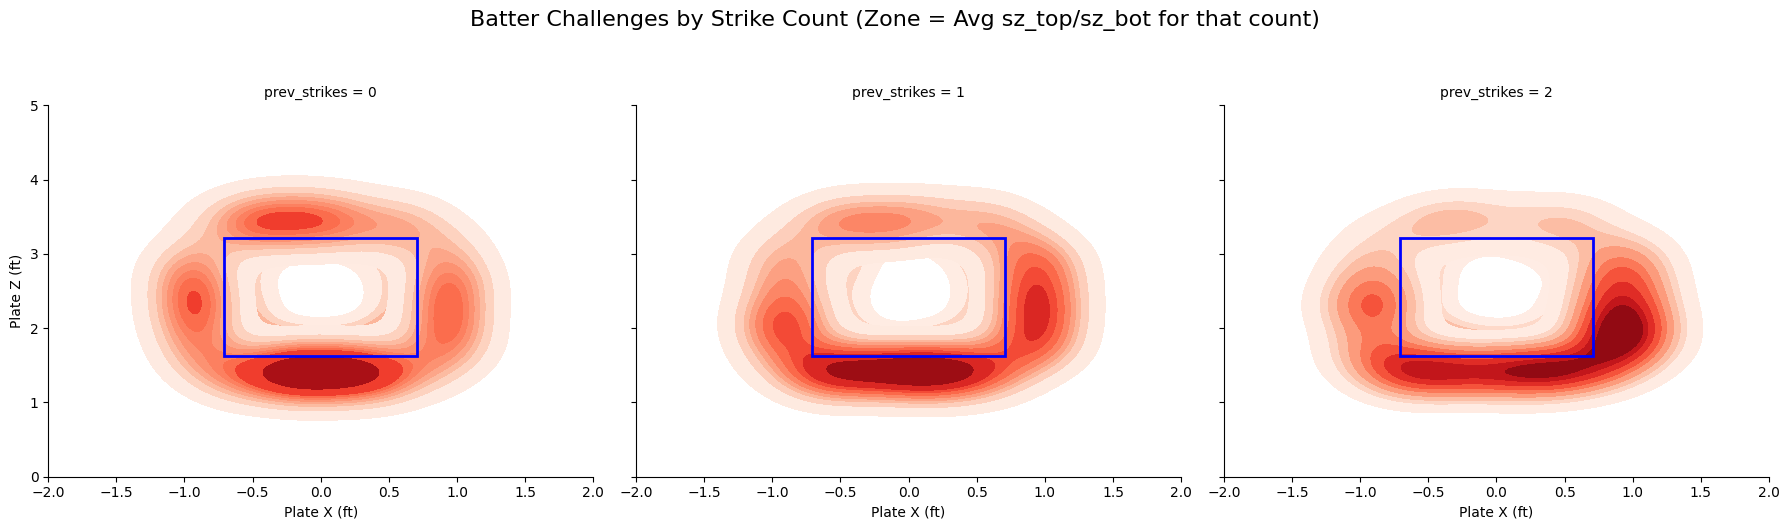

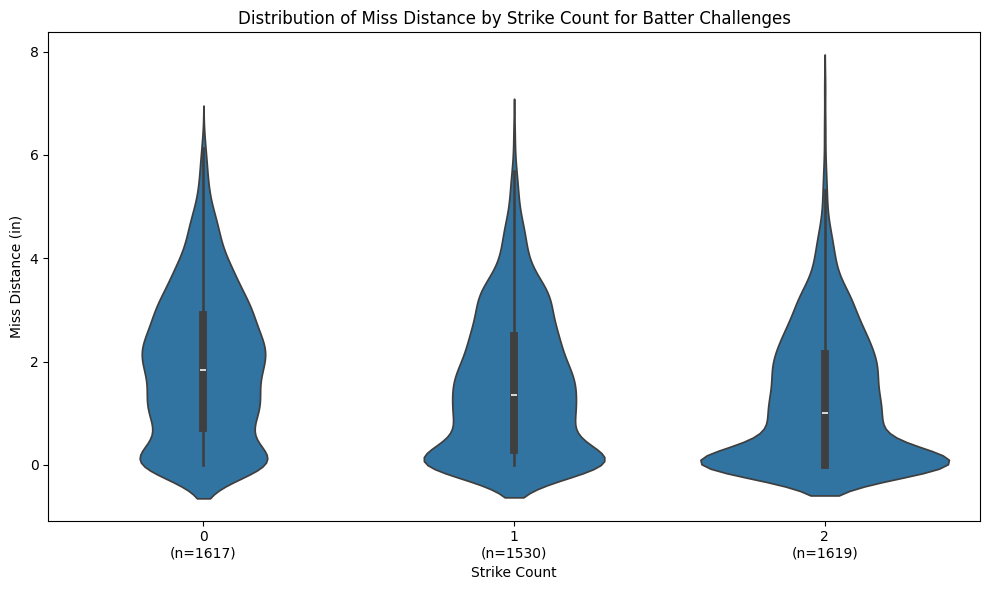

In [44]:

balls_plot = batter_challenges.copy()
balls_plot['result'] = balls_plot['overturned'].map({True: 'Overturned', False: 'Upheld'})

# Raw Pitch Plot
g = sns.FacetGrid(balls_plot, col='prev_strikes', hue='result', palette={'Overturned': 'green', 'Upheld': 'red'}, height=5, aspect=1.2)
g.map(sns.scatterplot, 'plate_x', 'plate_z', alpha=0.6,s = 30)

# Add the average strike zone rectangle for each strike count
for ax, strikes in zip(g.axes.flat, sorted(balls_plot['prev_strikes'].unique())):
    subset = balls_plot[balls_plot['prev_strikes'] == strikes]
    zone_bottom = subset['sz_bot'].mean()
    zone_top = subset['sz_top'].mean()
    
    ax.add_patch(plt.Rectangle((-17/24, zone_bottom), 34/24, zone_top - zone_bottom, fill=False, edgecolor='blue', linewidth=2))
    
    ax.set_xlim(-2, 2)
    ax.set_ylim(0, 5)
    
g.add_legend(title='Challenge Result')
g.set_axis_labels('Plate X (ft)', 'Plate Z (ft)')
g.fig.suptitle('Batter Challenges by Strike Count (Zone = Avg sz_top/sz_bot for that count)', fontsize=16, y = 1.05)
plt.tight_layout()
plt.show()

#KDE Plot
g = sns.FacetGrid(balls_plot, col='prev_strikes', hue='result', palette={'Overturned': 'green', 'Upheld': 'red'}, height=5, aspect=1.2)
g.map(sns.kdeplot, 'plate_x', 'plate_z', fill=True, cmap='Reds', levels=10, thresh=0.05)

# Add the average strike zone rectangle for each strike count
for ax, strikes in zip(g.axes.flat, sorted(balls_plot['prev_strikes'].unique())):
    subset = balls_plot[balls_plot['prev_strikes'] == strikes]
    zone_bottom = subset['sz_bot'].mean()
    zone_top = subset['sz_top'].mean()
    
    ax.add_patch(plt.Rectangle((-17/24, zone_bottom), 34/24, zone_top - zone_bottom, fill=False, edgecolor='blue', linewidth=2))
    
    ax.set_xlim(-2, 2)
    ax.set_ylim(0, 5)
    
g.set_axis_labels('Plate X (ft)', 'Plate Z (ft)')
g.fig.suptitle('Batter Challenges by Strike Count (Zone = Avg sz_top/sz_bot for that count)', fontsize=16, y = 1.05)
plt.tight_layout()
plt.show()

#Violin Plot Miss Distance
fig, ax = plt.subplots(figsize=(10, 6))
balls_plot['miss_distance_inches'] = balls_plot['miss_distance'] * 12  # Convert to inches
sns.violinplot(data = balls_plot, x='prev_strikes', y='miss_distance_inches', ax=ax)

counts = balls_plot['prev_strikes'].value_counts().sort_index()
labels = [f"{strikes}\n(n={counts[strikes]})" for strikes in counts.index]
ax.set_xticks(range(len(labels))) 
ax.set_xticklabels(labels)
ax.set_title('Distribution of Miss Distance by Strike Count for Batter Challenges')
ax.set_xlabel('Strike Count')
ax.set_ylabel('Miss Distance (in)')
plt.tight_layout()
plt.show()

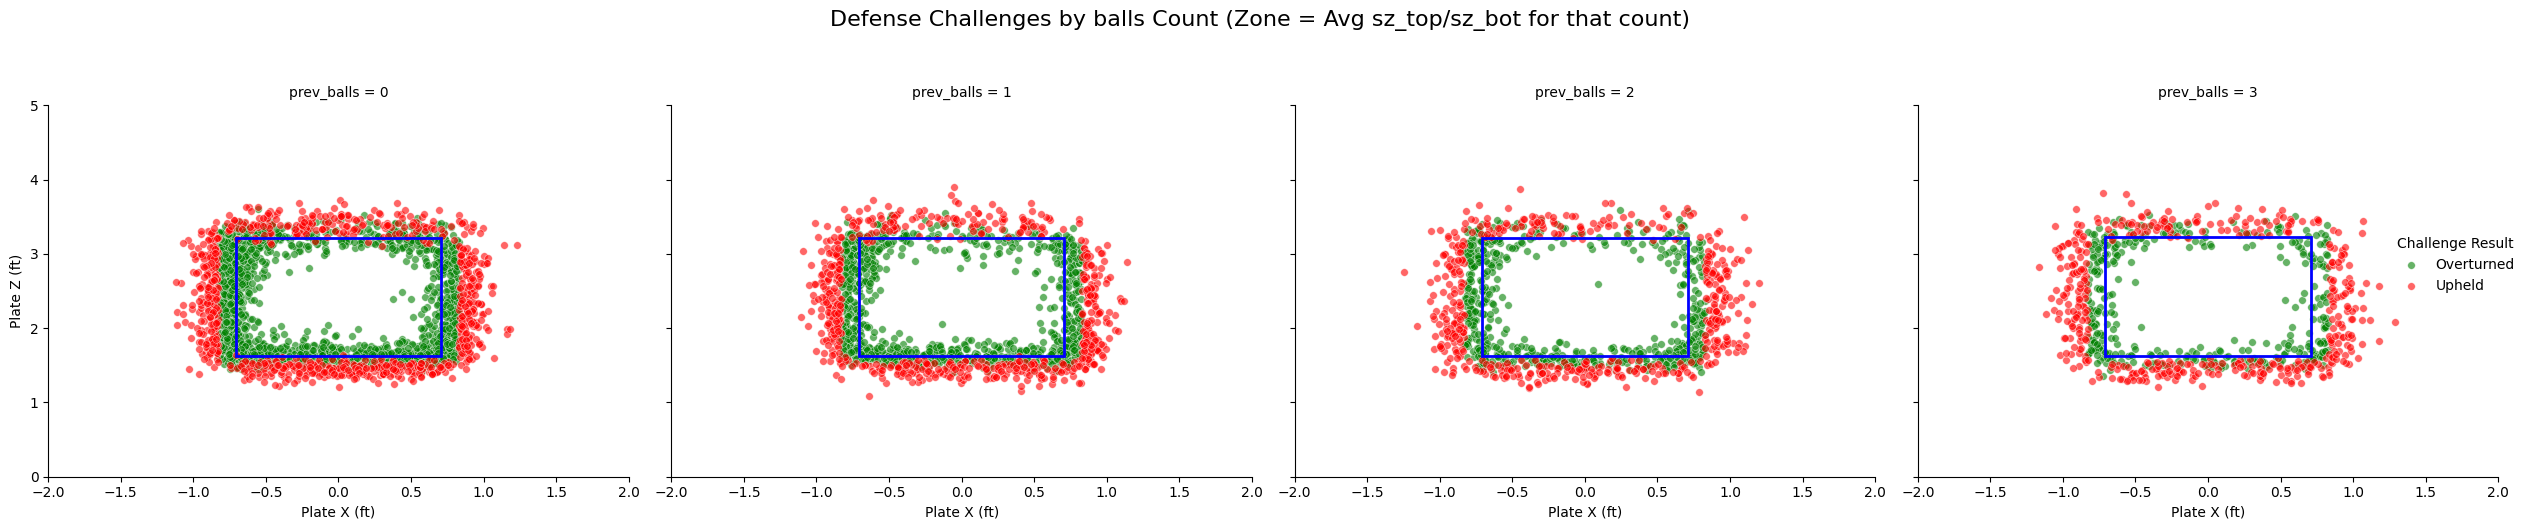

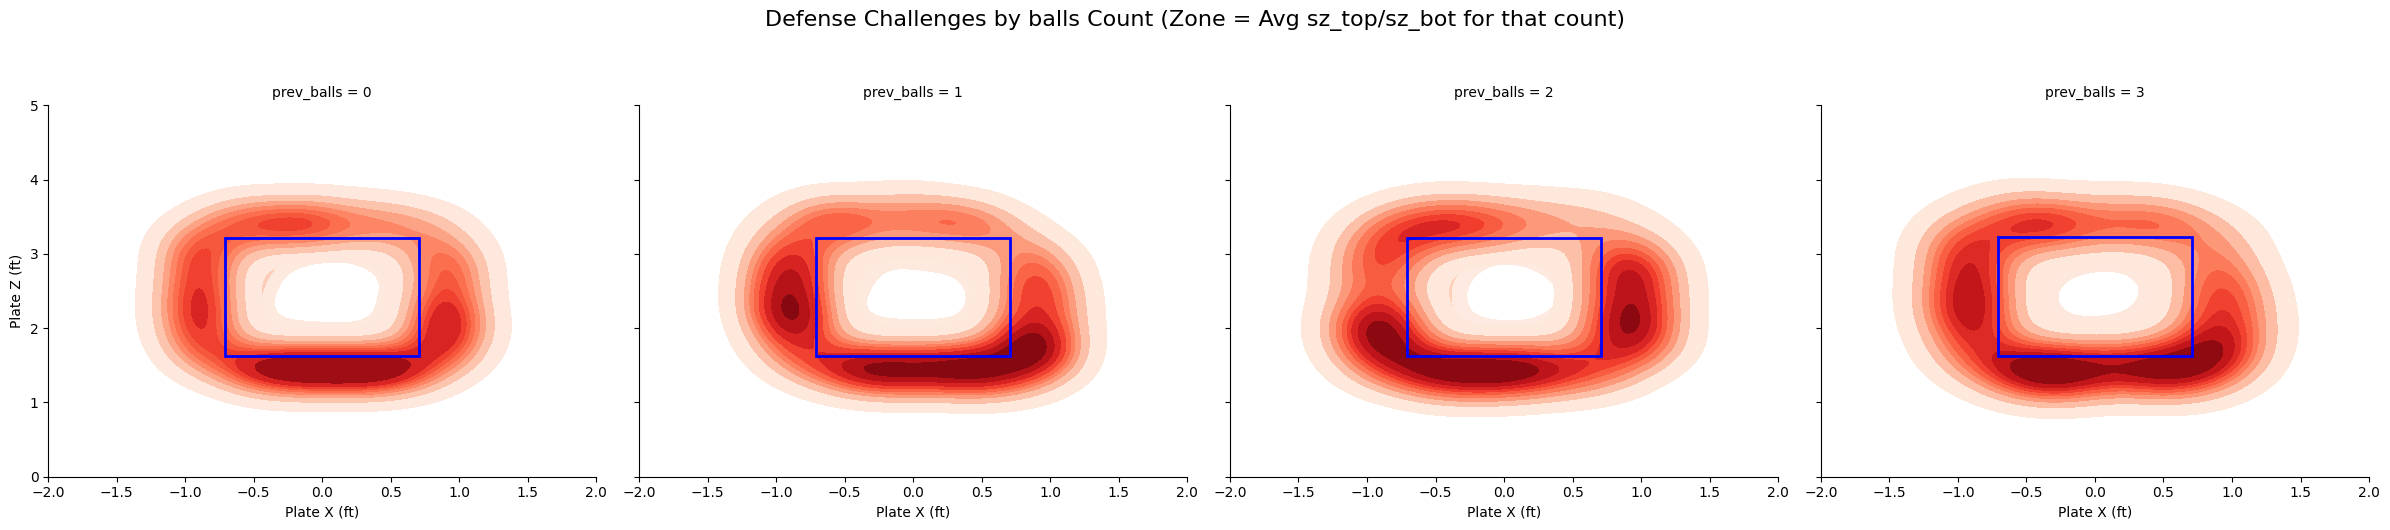

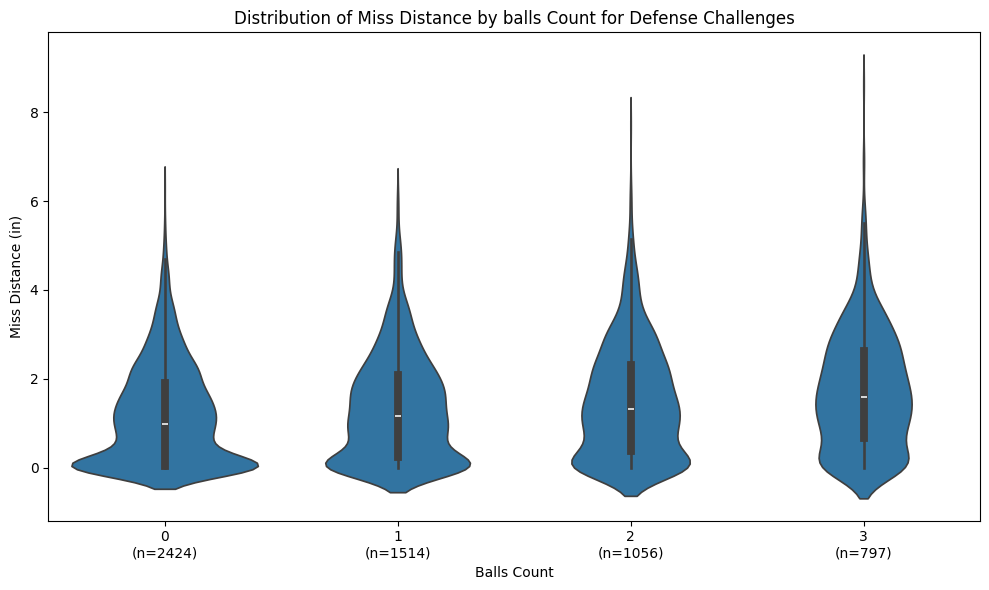

In [45]:
defense_challenges_plot = defense_challenges.copy()
defense_challenges_plot['result'] = defense_challenges_plot['overturned'].map({True: 'Overturned', False: 'Upheld'})

#Raw Pitch Plot
g = sns.FacetGrid(defense_challenges_plot, col='prev_balls', hue='result', palette={'Overturned': 'green', 'Upheld': 'red'}, height=5, aspect=1.2)
g.map(sns.scatterplot, 'plate_x', 'plate_z', alpha=0.6,s = 30)

# Add the average strike zone rectangle for each ball count
for ax, ballss in zip(g.axes.flat, sorted(defense_challenges_plot['prev_balls'].unique())):
    subset = defense_challenges_plot[defense_challenges_plot['prev_balls'] == ballss]
    zone_bottom = subset['sz_bot'].mean()
    zone_top = subset['sz_top'].mean()
    
    ax.add_patch(plt.Rectangle((-17/24, zone_bottom), 34/24, zone_top - zone_bottom, fill=False, edgecolor='blue', linewidth=2))
    
    ax.set_xlim(-2, 2)
    ax.set_ylim(0, 5)
    
g.add_legend(title='Challenge Result')
g.set_axis_labels('Plate X (ft)', 'Plate Z (ft)')
g.fig.suptitle('Defense Challenges by balls Count (Zone = Avg sz_top/sz_bot for that count)', fontsize=16, y = 1.05)
plt.tight_layout()
plt.show()

#KDE Plot
g = sns.FacetGrid(defense_challenges_plot, col='prev_balls', hue='result', palette={'Overturned': 'green', 'Upheld': 'red'}, height=5, aspect=1.2)
g.map(sns.kdeplot, 'plate_x', 'plate_z', fill=True, cmap='Reds', levels=10, thresh=0.05)

# Add the average strike zone rectangle for each ball count
for ax, ballss in zip(g.axes.flat, sorted(defense_challenges_plot['prev_balls'].unique())):
    subset = defense_challenges_plot[defense_challenges_plot['prev_balls'] == ballss]
    zone_bottom = subset['sz_bot'].mean()
    zone_top = subset['sz_top'].mean()
    
    ax.add_patch(plt.Rectangle((-17/24, zone_bottom), 34/24, zone_top - zone_bottom, fill=False, edgecolor='blue', linewidth=2))
    
    ax.set_xlim(-2, 2)
    ax.set_ylim(0, 5)
    
g.set_axis_labels('Plate X (ft)', 'Plate Z (ft)')
g.fig.suptitle('Defense Challenges by balls Count (Zone = Avg sz_top/sz_bot for that count)', fontsize=16, y = 1.05)
plt.tight_layout()
plt.show()

#Violin Plot Miss Distance
fig, ax = plt.subplots(figsize=(10, 6))
defense_challenges_plot['miss_distance_inches'] = defense_challenges_plot['miss_distance'] * 12  # Convert to inches
sns.violinplot(data = defense_challenges_plot, x='prev_balls', y='miss_distance_inches', ax=ax)

counts = defense_challenges_plot['prev_balls'].value_counts().sort_index()
labels = [f"{ballss}\n(n={counts[ballss]})" for ballss in counts.index]
ax.set_xticks(range(len(labels))) 
ax.set_xticklabels(labels)
ax.set_title('Distribution of Miss Distance by balls Count for Defense Challenges')
ax.set_xlabel('Balls Count')
ax.set_ylabel('Miss Distance (in)')
plt.tight_layout()
plt.show()